# 01 · Análisis exploratorio y territorial (Paso 05)

**Proyecto:** UrbanSafe CABA · **Skills aplicadas:** `geospatial-analysis`, `statistical-analysis`, `visualize-data` y `jupyter-notebooks`

**Propósito.** Interpretar los patrones de la siniestralidad registrada, no solo graficarla. Cada hallazgo se presenta con su evidencia, su interpretación y sus limitaciones. La síntesis está en [docs/eda_findings.md](../docs/eda_findings.md).

| Elemento | Detalle |
|---|---|
| Entradas | `data/processed/` (ETL del Paso 04: `python -m src.data_processing`), `data/raw/limites/barrios.geojson` y, solo para el análisis 7, `data/raw/red_vial/` |
| Población observada | Siniestros **con víctimas** registrados por sumario policial (F01–F03). No incluye siniestros con solo daños materiales. |
| Período | **Desarrollo: 2019-01 a 2024-12.** El test provisorio de 2025 **no se usa** en este notebook. |
| Unidades | Hechos, víctimas, barrio (48) × mes; comuna como contraste |
| Salidas | `reports/figures/01_EDA/`, `reports/tables/01_EDA/` y `eda_metrics.json` |

**Convenciones.**
- Los conteos son **carga registrada**, no riesgo: no hay un denominador de exposición (D8).
- Los meses `registro` (2019-11/12) y `pandemia` (2020-03 a 2021-05) están marcados (D3).
- La infraestructura vial solo se describe; no entra en ningún modelo (D11).
- Los contrastes estadísticos son **exploratorios**: hay dependencia temporal y espacial, y no se corrigen comparaciones múltiples.

### Guía para el lector

**La pregunta, en una frase.** ¿Qué patrones muestran los siniestros con víctimas registrados en CABA entre 2019 y 2024: cuándo ocurren, dónde, a quiénes y qué tan estables son?

**Dónde encaja.** Usa los datos limpios del Paso 04 y **no toca 2025**, que está reservado para la evaluación final. Sus hallazgos, numerados E1 a E10 en [docs/eda_findings.md](../docs/eda_findings.md), justifican qué variables se construyen en el notebook 02 y anticipan qué tan difícil será superar al historial en los modelos.

**Cómo leerlo.** Hay ocho análisis. Cada uno termina en una **Lectura** con tres partes: *Evidencia* (las cifras), *Interpretación* (qué significan) y *Limitaciones* (qué no permiten afirmar).

**Hallazgos principales.**
1. **Tiempo.** Después de la caída por la pandemia, los hechos volvieron al nivel de 2019. Enero es el mes más bajo y octubre el más alto, y los días hábiles concentran más hechos que el fin de semana.
2. **Territorio.** Palermo tiene la mayor cantidad de hechos, pero está 21.º en densidad: el conteo mezcla tamaño del barrio e intensidad.
3. **Personas.** Las motos aparecen en alrededor del 45 % de los hechos con modo informado. Motos y peatones suman el 81 % de los hechos mortales.
4. **Horario.** La madrugada (0 a 5 h) concentra solo el 7,9 % de los hechos, pero con el doble de proporción de graves o mortales.
5. **Concentración y persistencia.** En promedio, el 68 % de los 10 barrios con más hechos de un mes repite el mes siguiente.
6. **Pandemia.** Cambió el nivel y los medios de transporte, no la geografía de los siniestros.
7. **Avenidas.** Concentran el 64 % de los hechos con el 23,5 % de los kilómetros de calle. Es una descripción, no una causa.
8. **Registro.** Los faltantes no son aleatorios: los hechos graves pierden la ubicación con más frecuencia.

**Qué implica para los modelos.** El historial reciente será un competidor fuerte. Conviene incluir el nivel reciente, el mes del año, los barrios vecinos y la superficie; tratar «sin dato» como categoría propia; y usar la gravedad solo para describir.

### Glosario y variables de este notebook

| Término | Significado |
|---|---|
| **Carga registrada** | Cantidad de hechos con víctimas registrados. **No es riesgo**: no hay datos de cuántas personas o vehículos circulan por cada barrio. |
| **Densidad** | Hechos por km² de superficie del barrio y por año. Corrige por tamaño, no por tránsito. |
| **KSI; SD** | Hecho con alguna víctima grave o mortal; «sin dato». |
| **STL** | Descomposición de una serie en tendencia, estacionalidad y resto. |
| **Índice estacional** | Hechos de un mes divididos por el promedio de su año: 1,10 indica 10 % por encima de lo habitual. |
| **Intervalo de Wilson** | Margen de incertidumbre para una proporción (por ejemplo, el porcentaje de graves a una hora dada). |
| **Lorenz y Gini** | Curva y coeficiente de concentración de los hechos entre barrios. |
| **I de Moran; vecindad *queen*** | Mide si los barrios con valores altos están juntos. Dos barrios son vecinos *queen* si comparten límite. |
| **Jaccard** | Proporción de barrios que coinciden entre dos listas, por ejemplo, el top 10 de dos años. |
| **D3, D5, D6, D8, D11** | Decisiones del notebook 00 (marcas de meses anómalos, objetivo, top 10, exposición e infraestructura). |

**Variables que se usan** (definiciones completas en el [diccionario de datos](../docs/data_dictionary.md)):

| Variable | Qué es |
|---|---|
| `y_hechos` | Hechos con víctimas de un barrio en un mes (panel barrio × mes) |
| `y_ksi` | Hechos graves o mortales del barrio en el mes; solo descriptivo |
| `hechos_modo_*` | Hechos por modo de la víctima: auto, bicicleta, moto, peatón, transporte público, otros y SD |
| `area_km2` | Superficie oficial del barrio |
| `anomalia_mes` | `registro` (nov–dic 2019), `pandemia` (mar 2020–may 2021) o `ninguna` |
| `fecha`, `hora_entera`, `dia_semana` | Momento del hecho |
| `modo_victima`, `tipo_de_via`, `gravedad`, `ksi` | Atributos de cada hecho |
| `barrio`, `comuna`, `lat`, `lon` | Ubicación asignada según la regla D9 |

## 0. Parámetros y carga

> **Qué hace la celda siguiente.** Carga los datos procesados por el ETL (hechos, víctimas y panel barrio × mes) y los límites de barrios, y se queda solo con el período de desarrollo. **Qué mirar en la salida:** 54.066 hechos y 3.456 filas barrio-mes, es decir, 48 barrios × 72 meses de 2019–2024.

In [1]:
import json, unicodedata, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore", category=RuntimeWarning)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import sys; sys.path.insert(0, str(ROOT))
from src.data_processing import CRS_CABA
from src.labels import top_k_labels

PROC, RAW = ROOT / "data" / "processed", ROOT / "data" / "raw"
FIG, TAB = ROOT / "reports" / "figures" / "01_EDA", ROOT / "reports" / "tables" / "01_EDA"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
assert (PROC / "panel_barrio_mes.csv").exists(), "Ejecute primero: python -m src.data_processing --download"
SEED = 20261110; rng = np.random.default_rng(SEED)
DEV_END = "2024-12"
M = {}   # métricas para eda_metrics.json

# Paleta (skill dataviz, instancia de referencia validada): categórica en orden fijo y secuencial azul
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
SEQ2 = LinearSegmentedColormap.from_list("seq_orange", ["#fde3d6", "#f6a47f", "#eb6834", "#b84413", "#7a2a08"])
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10, "axes.axisbelow": True})
FUENTE = "Fuente: BA Data, Siniestros viales (OMSV, GCBA). Hechos con víctimas, 2019–2024."
def save(fig, name, note=FUENTE):
    fig.text(0.01, 0.005, note, fontsize=7.5, color=INK2, ha="left", va="bottom")
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

h_all = pd.read_csv(PROC / "hechos_clean.csv", dtype={"mes": str, "barrio": str}, low_memory=False)
v_all = pd.read_csv(PROC / "victimas_clean.csv", low_memory=False)
pb_all = pd.read_csv(PROC / "panel_barrio_mes.csv", dtype={"mes": str})
pc_all = pd.read_csv(PROC / "panel_comuna_mes.csv", dtype={"mes": str})
barrios = gpd.read_file(RAW / "limites" / "barrios.geojson").rename(columns={"nombre": "barrio"})

h = h_all[h_all["particion"] == "desarrollo"].copy()
v = v_all[v_all["id_siniestro"].isin(h["id_siniestro"])].copy()
pb = pb_all[pb_all["particion"] == "desarrollo"].copy()
pc = pc_all[pc_all["particion"] == "desarrollo"].copy()
h["fecha"] = pd.to_datetime(h["fecha"])
assert h["mes"].max() <= DEV_END and pb["mes"].max() <= DEV_END
print(f"hechos {len(h):,} | víctimas {len(v):,} | panel barrio-mes {len(pb):,} | meses {pb['mes'].nunique()}")
M["n"] = {"hechos": len(h), "victimas": len(v), "hechos_en_panel_barrio": int(pb["y_hechos"].sum())}

hechos 54,066 | víctimas 62,078 | panel barrio-mes 3,456 | meses 72


## 1. Evolución temporal, tendencia y estacionalidad

- **Tendencia y estacionalidad:** descomposición STL robusta (período 12) de la serie mensual.
- **Perfil estacional:** índice mes del año = conteo del mes / media del año. Se calcula solo con años sin meses marcados completos (2022–2024), para que la pandemia y la caída de registro no lo distorsionen.
- **Día de la semana:** media diaria de hechos por día, en meses sin anomalía.

In [2]:
ms = h.groupby("mes").agg(hechos=("id_siniestro", "size"), ksi=("ksi", "sum"), victimas=("n_victimas", "sum"))
ms.index = pd.PeriodIndex(ms.index, freq="M")
flag = h.groupby("mes")["anomalia_mes"].first(); flag.index = pd.PeriodIndex(flag.index, freq="M")
stl = STL(ms["hechos"].astype(float).values, period=12, robust=True).fit()
dec = pd.DataFrame({"observado": ms["hechos"], "tendencia": stl.trend, "estacional": stl.seasonal, "residuo": stl.resid}, index=ms.index)
dec.to_csv(TAB / "t1_stl_mensual.csv")
anual = h.groupby(h["fecha"].dt.year).agg(hechos=("id_siniestro", "size"), ksi=("ksi", "sum"), mortales=("gravedad", lambda s: (s == "MORTAL").sum()))
anual["var_interanual_pct"] = (anual["hechos"].pct_change() * 100).round(1)
anual["ksi_pct"] = (anual["ksi"] / anual["hechos"] * 100).round(2)
norm = h[h["fecha"].dt.year.between(2022, 2024)]
mm = norm.groupby([norm["fecha"].dt.year, norm["fecha"].dt.month]).size().unstack(0)
idx_est = (mm / mm.mean()).mean(axis=1).rename("indice_estacional")
d_ok = h[h["anomalia_mes"] == "ninguna"]
ndias = d_ok.groupby(d_ok["fecha"].dt.day_of_week)["fecha"].nunique()
dsem = (d_ok.groupby(d_ok["fecha"].dt.day_of_week).size() / ndias).rename("hechos_por_dia")
dsem.index = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
anual.to_csv(TAB / "t1_anual.csv"); idx_est.to_csv(TAB / "t1_indice_estacional.csv"); dsem.to_csv(TAB / "t1_dia_semana.csv")
tr = dec["tendencia"]
M["temporal"] = {"anual": anual.reset_index().to_dict(orient="records"),
                 "tendencia_2022_01": round(float(tr[pd.Period("2022-01", "M")]), 1), "tendencia_2024_12": round(float(tr[pd.Period("2024-12", "M")]), 1),
                 "tendencia_2019_06": round(float(tr[pd.Period("2019-06", "M")]), 1),
                 "indice_estacional_min_max": {"mes_min": int(idx_est.idxmin()), "min": round(float(idx_est.min()), 3),
                                               "mes_max": int(idx_est.idxmax()), "max": round(float(idx_est.max()), 3)},
                 "dia_semana_min_max": {"min": dsem.idxmin(), "min_v": round(float(dsem.min()), 1), "max": dsem.idxmax(), "max_v": round(float(dsem.max()), 1)},
                 "var_resid_sobre_var_total": round(float(dec["residuo"].var() / dec["observado"].var()), 3)}
display(anual); print(M["temporal"])

,hechos,ksi,mortales,var_interanual_pct,ksi_pct
fecha,,,,,
2019,10155,476,103,NaN,4.69
2020,6061,222,79,-40.3,3.66
2021,7818,454,96,29.0,5.81
2022,9536,629,107,22.0,6.60
2023,9927,460,104,4.1,4.63
2024,10569,626,110,6.5,5.92


{'anual': [{'fecha': 2019, 'hechos': 10155, 'ksi': 476, 'mortales': 103, 'var_interanual_pct': nan, 'ksi_pct': 4.69}, {'fecha': 2020, 'hechos': 6061, 'ksi': 222, 'mortales': 79, 'var_interanual_pct': -40.3, 'ksi_pct': 3.66}, {'fecha': 2021, 'hechos': 7818, 'ksi': 454, 'mortales': 96, 'var_interanual_pct': 29.0, 'ksi_pct': 5.81}, {'fecha': 2022, 'hechos': 9536, 'ksi': 629, 'mortales': 107, 'var_interanual_pct': 22.0, 'ksi_pct': 6.6}, {'fecha': 2023, 'hechos': 9927, 'ksi': 460, 'mortales': 104, 'var_interanual_pct': 4.1, 'ksi_pct': 4.63}, {'fecha': 2024, 'hechos': 10569, 'ksi': 626, 'mortales': 110, 'var_interanual_pct': 6.5, 'ksi_pct': 5.92}], 'tendencia_2022_01': 738.3, 'tendencia_2024_12': 894.4, 'tendencia_2019_06': 891.4, 'indice_estacional_min_max': {'mes_min': 1, 'min': 0.75, 'mes_max': 10, 'max': 1.101}, 'dia_semana_min_max': {'min': 'dom', 'min_v': 17.3, 'max': 'vie', 'max_v': 32.3}, 'var_resid_sobre_var_total': 0.492}


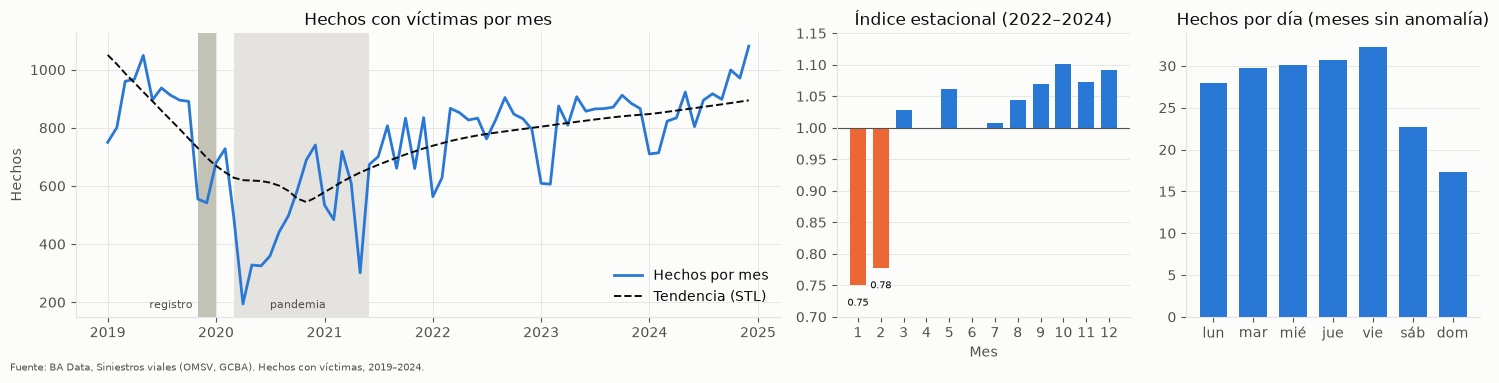

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2.4, 1, 1]})
ax = axes[0]; x = dec.index.to_timestamp()
for lab, col in [("registro", "#c3c2b7"), ("pandemia", "#e4e3df")]:
    for p in flag[flag == lab].index:
        ax.axvspan(p.to_timestamp(), (p + 1).to_timestamp(), color=col, lw=0)
ax.plot(x, dec["observado"], color=CAT[0], label="Hechos por mes")
ax.plot(x, dec["tendencia"], color=INK, lw=1.4, ls="--", label="Tendencia (STL)")
ax.set_title("Hechos con víctimas por mes"); ax.set_ylabel("Hechos")
ax.text(pd.Timestamp("2020-07-01"), ax.get_ylim()[0] + 30, "pandemia", color=INK2, fontsize=8)
ax.text(pd.Timestamp("2019-10-15"), ax.get_ylim()[0] + 30, "registro", color=INK2, fontsize=8, ha="right")
ax.legend(frameon=False, loc="lower right")
axes[1].bar(idx_est.index, idx_est.values - 1, bottom=1, color=[CAT[1] if v < 1 else CAT[0] for v in idx_est.values], width=.7)
axes[1].axhline(1, color=INK2, lw=.8); axes[1].set_ylim(.7, 1.15); axes[1].set_xticks(range(1, 13)); axes[1].grid(axis="x", visible=False)
for m_, v_ in idx_est.items():
    if v_ < .9: axes[1].text(m_, v_ - .02, f"{v_:.2f}", ha="center", va="top", fontsize=7.5, color=INK)
axes[1].set_title("Índice estacional (2022–2024)"); axes[1].set_xlabel("Mes")
axes[2].bar(dsem.index, dsem.values, color=CAT[0], width=.7); axes[2].set_title("Hechos por día (meses sin anomalía)"); axes[2].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "f1_temporal")

**Lectura (1).**
- **Evidencia.** Hechos por año: 10.155 (2019), 6.061 (2020; −40 %), 7.818, 9.536, 9.927 y 10.569 (2024). La tendencia STL pasa de unos 738 hechos por mes a comienzos de 2022 a unos 894 a fines de 2024, un nivel comparable al de mediados de 2019 (unos 891). En 2022–2024, **enero es el mes más bajo** (índice 0,75) y **octubre el más alto** (1,10). Los días hábiles concentran más hechos que el fin de semana: el viernes tiene 32,3 por día y el domingo 17,3. El residuo de la STL explica cerca de la mitad de la varianza de la serie, incluida la pandemia.
- **Interpretación.** La serie combina una tendencia de recuperación posterior a la pandemia, una estacionalidad marcada (el receso de verano en enero) y un ciclo semanal compatible con la movilidad laboral. Para pronosticar el mes siguiente, el nivel reciente y el mes calendario son señales necesarias.
- **Limitaciones.** El índice estacional usa solo tres años. No se puede separar si la recuperación de 2022–2024 es de movilidad o de registro (análisis 8). El componente de tendencia de la STL es menos confiable en los extremos de la serie.

## 2. Distribución territorial

Se presentan tres lecturas que no deben confundirse:
- **conteo** (carga registrada);
- **densidad por superficie** (hechos por km² y año);
- **participación** en el total de la ciudad.

Ninguna es riesgo ajustado por exposición. El período es 2019–2024, con hechos asignados a barrio según D9.

In [4]:
tb = pb.groupby("barrio").agg(hechos=("y_hechos", "sum"), ksi=("y_ksi", "sum"), area_km2=("area_km2", "first"), comuna=("comuna_barrio", "first"))
tb["hechos_km2_anio"] = (tb["hechos"] / 6 / tb["area_km2"]).round(1)
tb["participacion_pct"] = (tb["hechos"] / tb["hechos"].sum() * 100).round(2)
tb["ksi_pct"] = (tb["ksi"] / tb["hechos"] * 100).round(2)
tb["rank_conteo"] = tb["hechos"].rank(ascending=False, method="min").astype(int)
tb["rank_densidad"] = tb["hechos_km2_anio"].rank(ascending=False, method="min").astype(int)
tb = tb.sort_values("hechos", ascending=False); tb.to_csv(TAB / "t2_barrios.csv")
rho_cd = stats.spearmanr(tb["hechos"], tb["hechos_km2_anio"]).statistic
rho_ca = stats.spearmanr(tb["hechos"], tb["area_km2"]).statistic
M["territorial"] = {"top5_conteo": tb.head(5)[["hechos", "participacion_pct"]].reset_index().to_dict(orient="records"),
                    "top5_densidad": tb.sort_values("hechos_km2_anio", ascending=False).head(5)[["hechos_km2_anio"]].reset_index().to_dict(orient="records"),
                    "spearman_conteo_densidad": round(float(rho_cd), 3), "spearman_conteo_area": round(float(rho_ca), 3),
                    "min_conteo": tb.tail(1)[["hechos"]].reset_index().to_dict(orient="records")}
display(tb.head(10)); print(M["territorial"])

,hechos,ksi,area_km2,comuna,hechos_km2_anio,participacion_pct,ksi_pct,rank_conteo,rank_densidad
barrio,,,,,,,,,
Palermo,4059,224,15.9216,14,42.5,7.85,5.52,1,21
Balvanera,2767,97,4.3420,3,106.2,5.35,3.51,2,2
Flores,2477,128,8.5903,7,48.1,4.79,5.17,3,16
Caballito,2252,78,6.8506,6,54.8,4.36,3.46,4,11
Recoleta,1996,92,6.4330,2,51.7,3.86,4.61,5,12
Belgrano,1821,127,8.0595,13,37.7,3.52,6.97,6,29
Almagro,1734,58,4.0505,5,71.3,3.35,3.34,7,7
Saavedra,1659,123,5.5383,12,49.9,3.21,7.41,8,14
Villa Crespo,1645,67,3.6158,15,75.8,3.18,4.07,9,6


{'top5_conteo': [{'barrio': 'Palermo', 'hechos': 4059, 'participacion_pct': 7.85}, {'barrio': 'Balvanera', 'hechos': 2767, 'participacion_pct': 5.35}, {'barrio': 'Flores', 'hechos': 2477, 'participacion_pct': 4.79}, {'barrio': 'Caballito', 'hechos': 2252, 'participacion_pct': 4.36}, {'barrio': 'Recoleta', 'hechos': 1996, 'participacion_pct': 3.86}], 'top5_densidad': [{'barrio': 'Constitucion', 'hechos_km2_anio': 118.5}, {'barrio': 'Balvanera', 'hechos_km2_anio': 106.2}, {'barrio': 'Monserrat', 'hechos_km2_anio': 101.6}, {'barrio': 'San Nicolas', 'hechos_km2_anio': 90.7}, {'barrio': 'San Cristobal', 'hechos_km2_anio': 87.8}], 'spearman_conteo_densidad': 0.522, 'spearman_conteo_area': 0.664, 'min_conteo': [{'barrio': 'Coghlan', 'hechos': 209}]}


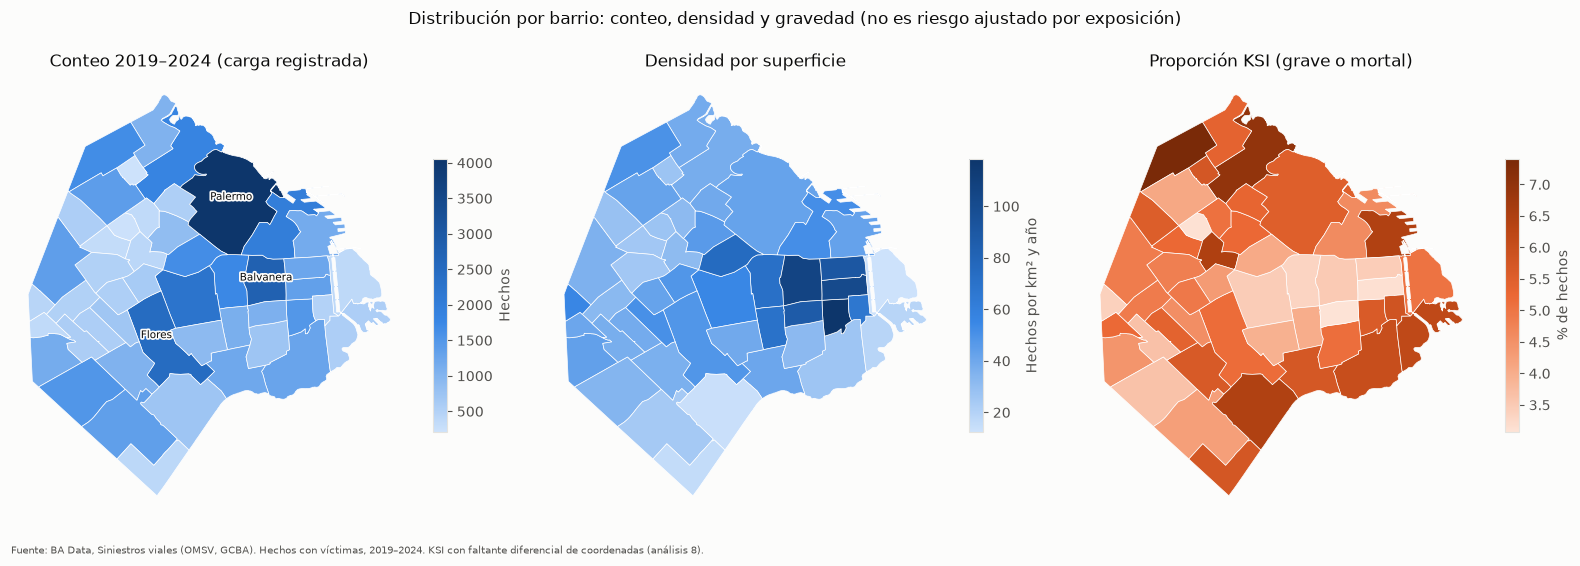

In [5]:
gb = barrios.merge(tb.reset_index(), on="barrio")
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, col, t, lab in [(axes[0], "hechos", "Conteo 2019–2024 (carga registrada)", "Hechos"),
                        (axes[1], "hechos_km2_anio", "Densidad por superficie", "Hechos por km² y año"),
                        (axes[2], "ksi_pct", "Proporción KSI (grave o mortal)", "% de hechos")]:
    gb.plot(column=col, cmap=SEQ if col != "ksi_pct" else SEQ2, legend=True, ax=ax, edgecolor="white", lw=.5,
            legend_kwds={"shrink": .55, "label": lab})
    ax.set_axis_off(); ax.set_title(t)
for _, r in gb.nlargest(3, "hechos").iterrows():
    c = r.geometry.representative_point()
    axes[0].annotate(r["barrio"], (c.x, c.y), fontsize=7.5, ha="center", color=INK, path_effects=[matplotlib.patheffects.withStroke(linewidth=2.5, foreground=SURFACE)])
fig.suptitle("Distribución por barrio: conteo, densidad y gravedad (no es riesgo ajustado por exposición)", y=.98)
fig.tight_layout(); save(fig, "f2_mapas_barrio", FUENTE + " KSI con faltante diferencial de coordenadas (análisis 8).")

**Lectura (2).**
- **Evidencia.** Palermo concentra el mayor conteo (4.059 hechos; 7,9 % del total), pero ocupa el **puesto 21 en densidad**. Las mayores densidades están en el centro y el centro-sur: Constitución (118,5 hechos por km² y año), Balvanera (106,2), Monserrat (101,6), San Nicolás (90,7) y San Cristóbal (87,8). El conteo se correlaciona más con la superficie del barrio (Spearman 0,66) que con la densidad (0,52). Entre los barrios de mayor conteo, la proporción KSI va de 3,3 % (Almagro) a 7,4 % (Saavedra). En el mapa, los barrios centrales tienen menor proporción KSI que la periferia norte y sur.
- **Interpretación.** El ranking por conteo, que define el objetivo de clasificación, mezcla tamaño e intensidad: un barrio grande puede estar en el top 10 sin ser denso. Esto no invalida el objetivo, porque la decisión operativa es dónde se concentra la carga, pero obliga a presentar siempre la densidad junto al conteo y a incluir la superficie como atributo territorial (Paso 06).
- **Limitaciones.** No hay denominador de exposición: la densidad por superficie no es riesgo. La proporción KSI por barrio está afectada por el faltante diferencial de coordenadas de los graves (análisis 8) y debe leerse como descriptiva.

## 3. Participación de peatones, motociclistas, ciclistas y automovilistas

Se usa el **modo de la víctima informado en el hecho** (`modo_victima`) y, como contraste, el modo de cada víctima (F02). SD se informa aparte y no se reparte. Se presentan las participaciones con y sin SD en el denominador, y la proporción KSI por modo (severidad relativa).

In [6]:
MODOS = ["MOTO", "PEATON", "BICICLETA", "AUTO", "TRANSPORTE PUBLICO"]
h["modo5"] = np.where(h["modo_victima"].isin(MODOS), h["modo_victima"], np.where(h["modo_victima"] == "SD", "SD", "OTROS"))
sh = pd.crosstab(h["fecha"].dt.year, h["modo5"], normalize="index").mul(100).round(1)[MODOS + ["OTROS", "SD"]]
sh_sin_sd = pd.crosstab(h.loc[h["modo5"] != "SD", "fecha"].dt.year, h.loc[h["modo5"] != "SD", "modo5"], normalize="index").mul(100).round(1)[MODOS + ["OTROS"]]
sev = h.groupby("modo5").agg(hechos=("id_siniestro", "size"), ksi_pct=("ksi", lambda s: round(s.mean() * 100, 2)),
                             mortal_pct=("gravedad", lambda s: round((s == "MORTAL").mean() * 100, 2))).loc[MODOS + ["OTROS", "SD"]]
mort = h[h["gravedad"] == "MORTAL"]["modo5"].value_counts(normalize=True).mul(100).round(1)
vm = v["modo_victima"].where(v["modo_victima"].isin(MODOS + ["SD"]), "OTROS")
vict_mort = vm[v["gravedad"] == "MORTAL"].value_counts(normalize=True).mul(100).round(1)
sh.to_csv(TAB / "t3_participacion_modo_anual.csv"); sev.to_csv(TAB / "t3_severidad_por_modo.csv")
M["actores"] = {"participacion_sin_sd_total": (h.loc[h["modo5"] != "SD", "modo5"].value_counts(normalize=True) * 100).round(1).to_dict(),
                "sd_pct_total": round(float((h["modo5"] == "SD").mean() * 100), 1),
                "severidad": sev.reset_index().to_dict(orient="records"),
                "participacion_en_hechos_mortales": mort.to_dict(), "participacion_en_victimas_mortales": vict_mort.to_dict()}
display(sh); display(sh_sin_sd); display(sev); print("Hechos mortales por modo (%):", mort.to_dict())

modo5,MOTO,PEATON,BICICLETA,AUTO,TRANSPORTE PUBLICO,OTROS,SD
fecha,,,,,,,
2019,39.0,16.3,10.0,12.0,6.0,6.9,9.7
2020,34.9,12.7,12.9,10.0,3.2,4.6,21.7
2021,31.1,11.8,12.2,8.2,4.0,3.3,29.5
2022,39.4,16.2,11.5,11.9,6.6,4.0,10.4
2023,40.5,14.8,10.3,13.3,5.9,3.4,11.8
2024,33.3,12.4,9.0,8.6,4.6,5.6,26.5


modo5,MOTO,PEATON,BICICLETA,AUTO,TRANSPORTE PUBLICO,OTROS
fecha,,,,,,
2019,43.2,18.1,11.1,13.2,6.7,7.7
2020,44.6,16.3,16.5,12.8,4.1,5.9
2021,44.1,16.7,17.2,11.6,5.6,4.7
2022,44.0,18.1,12.9,13.3,7.3,4.5
2023,45.9,16.8,11.6,15.0,6.7,3.8
2024,45.2,16.9,12.3,11.7,6.2,7.7


,hechos,ksi_pct,mortal_pct
modo5,,,
MOTO,19810,7.20,1.28
PEATON,7680,10.68,3.02
BICICLETA,5818,3.83,0.76
AUTO,5826,4.21,0.84
TRANSPORTE PUBLICO,2813,1.99,0.21
OTROS,2555,3.17,0.59
SD,9564,0.17,0.00


Hechos mortales por modo (%): {'MOTO': 42.2, 'PEATON': 38.7, 'AUTO': 8.2, 'BICICLETA': 7.3, 'OTROS': 2.5, 'TRANSPORTE PUBLICO': 1.0}


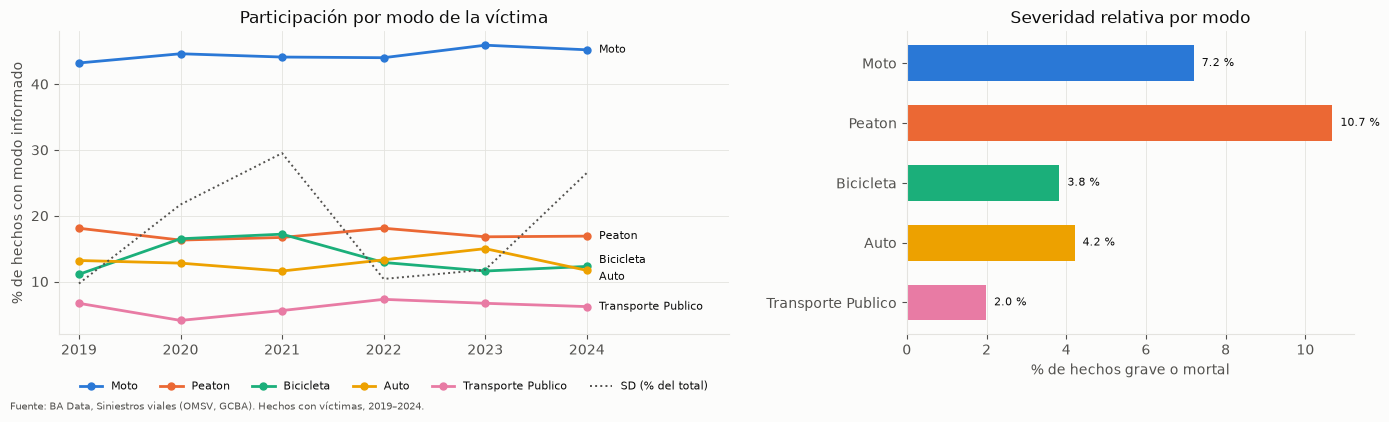

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for i, m in enumerate(MODOS):
    ax.plot(sh_sin_sd.index, sh_sin_sd[m], color=CAT[i], marker="o", ms=5, label=m.title())
    off = {"BICICLETA": 1.0, "AUTO": -1.0}.get(m, 0)
    ax.annotate(m.title(), (sh_sin_sd.index[-1] + .12, sh_sin_sd[m].iloc[-1] + off), color=INK, fontsize=8, va="center")
ax.plot(sh.index, sh["SD"], color=INK2, ls=":", lw=1.4, label="SD (% del total)")
ax.set_xlim(2018.8, 2025.4); ax.set_xticks(range(2019, 2025)); ax.set_ylabel("% de hechos con modo informado"); ax.set_title("Participación por modo de la víctima")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.12), ncol=6)
ax = axes[1]; y = np.arange(len(MODOS))
ax.barh(y, sev.loc[MODOS, "ksi_pct"], color=[CAT[i] for i in range(len(MODOS))], height=.6)
for i, val in enumerate(sev.loc[MODOS, "ksi_pct"]): ax.text(val + .2, i, f"{val:.1f} %", va="center", fontsize=8, color=INK)
ax.set_yticks(y, [m.title() for m in MODOS]); ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlabel("% de hechos grave o mortal"); ax.set_title("Severidad relativa por modo")
fig.tight_layout(); save(fig, "f3_actores")

**Lectura (3).**
- **Evidencia.** Entre los hechos con modo informado, la **moto** participa con 43–46 % todos los años. Le siguen el **peatón** (16–18 %), el **auto** (12–15 %), la **bicicleta** (11–13 %, con un salto a 16,5–17,2 % en 2020–2021) y el **transporte público** (4–7 %). La severidad relativa (proporción KSI) es mayor en el peatón (10,7 %; 3,0 % mortal) y la moto (7,2 %; 1,3 % mortal) que en el auto (4,2 %), la bicicleta (3,8 %) y el transporte público (2,0 %). Moto y peatón suman el **81 % de los hechos mortales** (42,2 % y 38,7 %). El modo SD representa entre 9,7 % y 29,5 % según el año, y **casi nunca corresponde a un hecho grave o mortal** (KSI 0,17 %; ningún mortal).
- **Interpretación.** La siniestralidad registrada es mayoritariamente de motociclistas, y la gravedad recae sobre los usuarios vulnerables (peatones y motociclistas), lo que coincide con el patrón internacional citado en la propuesta. Que el SD se concentre en hechos leves indica que **el faltante no es aleatorio**: las participaciones calculadas sin SD describen mejor los hechos graves que los leves.
- **Limitaciones.** El modo es un atributo del hecho (MIXTO agrupa varios modos). Sin exposición por modo, una mayor participación no implica un mayor riesgo por viaje. Las variables de composición del Paso 06 deberán tratar SD como una categoría explícita (feasibility_report, sección 5).

## 4. Patrones por hora y día

El primer gráfico es un mapa de calor de hechos por hora y día de la semana, con media por día calendario en meses sin anomalía. El segundo muestra la proporción KSI por franja horaria, con un intervalo de Wilson del 95 %. Los hechos sin hora (77 en el desarrollo) se excluyen de este análisis.

In [8]:
d = h[(h["anomalia_mes"] == "ninguna") & h["hora_entera"].notna()].copy()
d["dow"] = d["fecha"].dt.day_of_week; d["hh"] = d["hora_entera"].astype(int)
ndias = d.groupby("dow")["fecha"].nunique()
hm = d.groupby(["dow", "hh"]).size().unstack(fill_value=0).div(ndias, axis=0)
hm.index = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]; hm.to_csv(TAB / "t4_hora_dia.csv")
def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / den; hw = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return c - hw, c + hw
kh = d.groupby("hh")["ksi"].agg(["sum", "size"]); kh["pct"] = kh["sum"] / kh["size"] * 100
kh["lo"], kh["hi"] = zip(*[(a * 100, b * 100) for a, b in (wilson(k, n) for k, n in zip(kh["sum"], kh["size"]))])
kh.to_csv(TAB / "t4_ksi_por_hora.csv")
noche = d["hh"].isin([0, 1, 2, 3, 4, 5]); finde_noche = noche & d["dow"].isin([5, 6])
M["horario"] = {"pico_hora": int(d.groupby("hh").size().idxmax()), "pct_hechos_0_6h": round(float(noche.mean() * 100), 1),
                "ksi_pct_0_6h": round(float(d.loc[noche, "ksi"].mean() * 100), 2), "ksi_pct_7_23h": round(float(d.loc[~noche, "ksi"].mean() * 100), 2),
                "ksi_pct_finde_madrugada": round(float(d.loc[finde_noche, "ksi"].mean() * 100), 2),
                "sin_hora": int(h["hora_entera"].isna().sum())}
print(M["horario"])

{'pico_hora': 17, 'pct_hechos_0_6h': 7.9, 'ksi_pct_0_6h': 10.5, 'ksi_pct_7_23h': 4.9, 'ksi_pct_finde_madrugada': 10.64, 'sin_hora': 77}


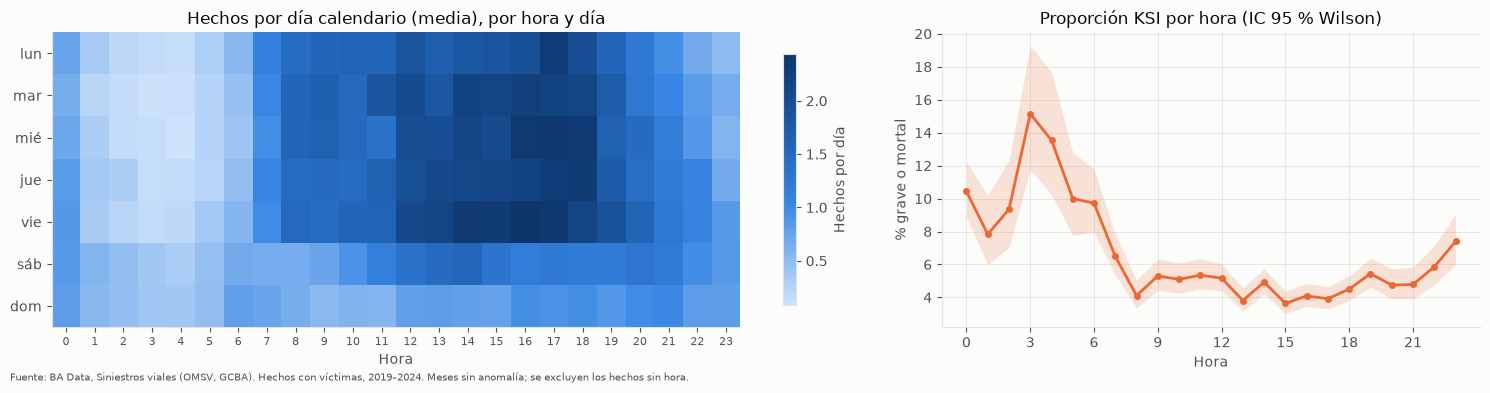

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1.6, 1]})
im = axes[0].imshow(hm.values, cmap=SEQ, aspect="auto"); axes[0].grid(False)
axes[0].set_xticks(range(24), range(24), fontsize=8); axes[0].set_yticks(range(7), hm.index)
axes[0].set_xlabel("Hora"); axes[0].set_title("Hechos por día calendario (media), por hora y día")
fig.colorbar(im, ax=axes[0], shrink=.85, label="Hechos por día")
axes[1].fill_between(kh.index, kh["lo"], kh["hi"], color=CAT[1], alpha=.18, lw=0)
axes[1].plot(kh.index, kh["pct"], color=CAT[1], marker="o", ms=4)
axes[1].set_xticks(range(0, 24, 3)); axes[1].set_xlabel("Hora"); axes[1].set_ylabel("% grave o mortal")
axes[1].set_title("Proporción KSI por hora (IC 95 % Wilson)")
fig.tight_layout(); save(fig, "f4_horario", FUENTE + " Meses sin anomalía; se excluyen los hechos sin hora.")

**Lectura (4).**
- **Evidencia.** En los días hábiles, los hechos se concentran entre las 8 y las 19 h, con pico a las 17 h. El fin de semana tiene un perfil más plano y el domingo es el día más bajo. De las 0 a las 5 h ocurre solo el **7,9 %** de los hechos, pero su proporción KSI es **10,5 %**, frente a 4,9 % en el resto del día: unas 2,1 veces. La proporción KSI máxima, alrededor del 15 %, se da a las 3 h, con un intervalo de Wilson visiblemente separado de las horas diurnas.
- **Interpretación.** La frecuencia sigue a la actividad diurna. La severidad, en cambio, es nocturna, lo que es compatible con mayores velocidades y menor tránsito, aunque **este análisis no identifica causas**. Para la priorización por frecuencia pesa más el día; una política orientada a la gravedad debería mirar la madrugada.
- **Limitaciones.** Hay 77 hechos sin hora. El intervalo de Wilson supone independencia entre hechos, que es razonable a esta escala pero no considera el agrupamiento por barrio. La hora es la registrada en el sumario.

## 5. Concentración espacial y persistencia de hotspots

**Concentración.**
- Curva de Lorenz y coeficiente de Gini por año, entre barrios.
- **Autocorrelación espacial:** I de Moran global de la densidad (hechos por km²) con vecindad *queen* (barrios que comparten límite), pesos estandarizados por fila y 9.999 permutaciones. Hipótesis nula: aleatoriedad espacial. Se informa la sensibilidad a usar conteos en lugar de densidades.

**Persistencia.**
- *Hotspot* anual: top 10 barrios por conteo del año. Se mide su superposición entre años (índice de Jaccard).
- *Hotspot* mensual: top 10 del mes con la regla R0 (D6.1). Se mide la proporción que se repite el mes siguiente.

**Microescala.** Grilla de 250 m: participación de la celda superior y persistencia del 5 % de celdas superiores entre 2022 y 2024.

In [10]:
yb = pb.groupby(["anio", "barrio"])["y_hechos"].sum().unstack(0)
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x); return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))
gin = {int(a): round(gini(yb[a]), 3) for a in yb.columns}
# Moran global
bm = barrios.to_crs(CRS_CABA).set_index("barrio").loc[tb.index.sort_values()]
W = np.array([[float(a.touches(b) or (a.intersects(b) and a is not b and a.intersection(b).length > 0)) for b in bm.geometry] for a in bm.geometry])
np.fill_diagonal(W, 0); islas = int((W.sum(1) == 0).sum()); Wr = W / W.sum(1, keepdims=True)
def moran(x, perms=9999):
    z = x - x.mean(); I = len(x) / Wr.sum() * (z @ Wr @ z) / (z @ z)
    sims = np.array([(lambda zp: len(x) / Wr.sum() * (zp @ Wr @ zp) / (zp @ zp))(rng.permutation(z)) for _ in range(perms)])
    return round(float(I), 3), round(float((np.sum(sims >= I) + 1) / (perms + 1)), 4), round(float(sims.mean()), 4)
dens = (tb.loc[bm.index, "hechos"] / tb.loc[bm.index, "area_km2"]).values
mor_d = moran(dens); mor_c = moran(tb.loc[bm.index, "hechos"].values.astype(float))
# Persistencia anual top 10
top = {a: set(yb[a].nlargest(10).index) for a in yb.columns}
jac = {f"{a}-{b}": round(len(top[a] & top[b]) / len(top[a] | top[b]), 3) for a, b in zip(list(top)[:-1], list(top)[1:])}
nucleo = set.intersection(*top.values())
# Persistencia mensual top 10 (R0)
pbt = pb[["barrio", "mes", "y_hechos"]].copy(); pbt["top"] = top_k_labels(pbt, "barrio", "mes", 10, ycol="y_hechos")
tm = pbt.pivot(index="barrio", columns="mes", values="top")
rep = [(tm.iloc[:, i] & tm.iloc[:, i + 1]).sum() / 10 for i in range(tm.shape[1] - 1)]
freq_top = tm.mean(axis=1).sort_values(ascending=False)
M["concentracion"] = {"gini_anual": gin, "moran_densidad": {"I": mor_d[0], "p_perm": mor_d[1], "E_I_perm": mor_d[2]},
                      "moran_conteo": {"I": mor_c[0], "p_perm": mor_c[1]}, "islas": islas, "vecinos_media": round(float(W.sum(1).mean()), 2),
                      "jaccard_top10_anual": jac, "nucleo_top10_todos_los_anios": sorted(nucleo),
                      "top10_mensual_repite_mes_siguiente": {"media": round(float(np.mean(rep)), 3), "min": round(float(np.min(rep)), 2), "max": round(float(np.max(rep)), 2)},
                      "barrios_top10_mas_de_80pct_meses": freq_top[freq_top > .8].round(3).to_dict(),
                      "barrios_nunca_top10": int((freq_top == 0).sum())}
freq_top.to_csv(TAB / "t5_frecuencia_top10_mensual.csv")
print(json.dumps(M["concentracion"], ensure_ascii=False, indent=1))

{
 "gini_anual": {
  "2019": 0.362,
  "2020": 0.352,
  "2021": 0.362,
  "2022": 0.37,
  "2023": 0.345,
  "2024": 0.365
 },
 "moran_densidad": {
  "I": 0.47,
  "p_perm": 0.0001,
  "E_I_perm": -0.0197
 },
 "moran_conteo": {
  "I": 0.207,
  "p_perm": 0.0079
 },
 "islas": 0,
 "vecinos_media": 5.21,
 "jaccard_top10_anual": {
  "2019-2020": 0.818,
  "2020-2021": 0.818,
  "2021-2022": 0.538,
  "2022-2023": 0.818,
  "2023-2024": 0.818
 },
 "nucleo_top10_todos_los_anios": [
  "Almagro",
  "Balvanera",
  "Belgrano",
  "Caballito",
  "Flores",
  "Palermo",
  "Recoleta"
 ],
 "top10_mensual_repite_mes_siguiente": {
  "media": 0.682,
  "min": 0.4,
  "max": 0.9
 },
 "barrios_top10_mas_de_80pct_meses": {
  "Balvanera": 1.0,
  "Palermo": 0.986,
  "Flores": 0.972,
  "Caballito": 0.903,
  "Recoleta": 0.861
 },
 "barrios_nunca_top10": 21
}


In [11]:
# Microescala: grilla de 250 m
pts = gpd.GeoDataFrame(h[h["lat"].notna()], geometry=gpd.points_from_xy(h.loc[h["lat"].notna(), "lon"], h.loc[h["lat"].notna(), "lat"]), crs=4326).to_crs(CRS_CABA)
cell = 250
pts["cx"] = (pts.geometry.x // cell).astype(int); pts["cy"] = (pts.geometry.y // cell).astype(int)
cab = barrios.to_crs(CRS_CABA).union_all(); minx, miny, maxx, maxy = cab.bounds
allc = [(i, j) for i in range(int(minx // cell), int(maxx // cell) + 1) for j in range(int(miny // cell), int(maxy // cell) + 1)
        if shapely.box(i * cell, j * cell, (i + 1) * cell, (j + 1) * cell).intersects(cab)]
cnt = pts.groupby(["cx", "cy"]).size().reindex(pd.MultiIndex.from_tuples(allc), fill_value=0)
s = cnt.sort_values(ascending=False); n = len(s)
by_y = {a: pts[pts["anio"] == a].groupby(["cx", "cy"]).size().reindex(cnt.index, fill_value=0) for a in (2022, 2024)}
k5 = int(np.ceil(n * .05)); t22, t24 = set(by_y[2022].nlargest(k5).index), set(by_y[2024].nlargest(k5).index)
M["microescala_250m"] = {"celdas": n, "celdas_sin_hechos_pct": round(float((s == 0).mean() * 100), 1),
                         "share_top1pct_celdas": round(float(s.iloc[: int(np.ceil(n * .01))].sum() / s.sum() * 100), 1),
                         "share_top5pct_celdas": round(float(s.iloc[:k5].sum() / s.sum() * 100), 1),
                         "jaccard_top5pct_2022_2024": round(len(t22 & t24) / len(t22 | t24), 3),
                         "spearman_celdas_2022_2024": round(float(stats.spearmanr(by_y[2022], by_y[2024]).statistic), 3)}
print(M["microescala_250m"])

{'celdas': 3473, 'celdas_sin_hechos_pct': 14.7, 'share_top1pct_celdas': 6.9, 'share_top5pct_celdas': 23.1, 'jaccard_top5pct_2022_2024': 0.328, 'spearman_celdas_2022_2024': 0.718}


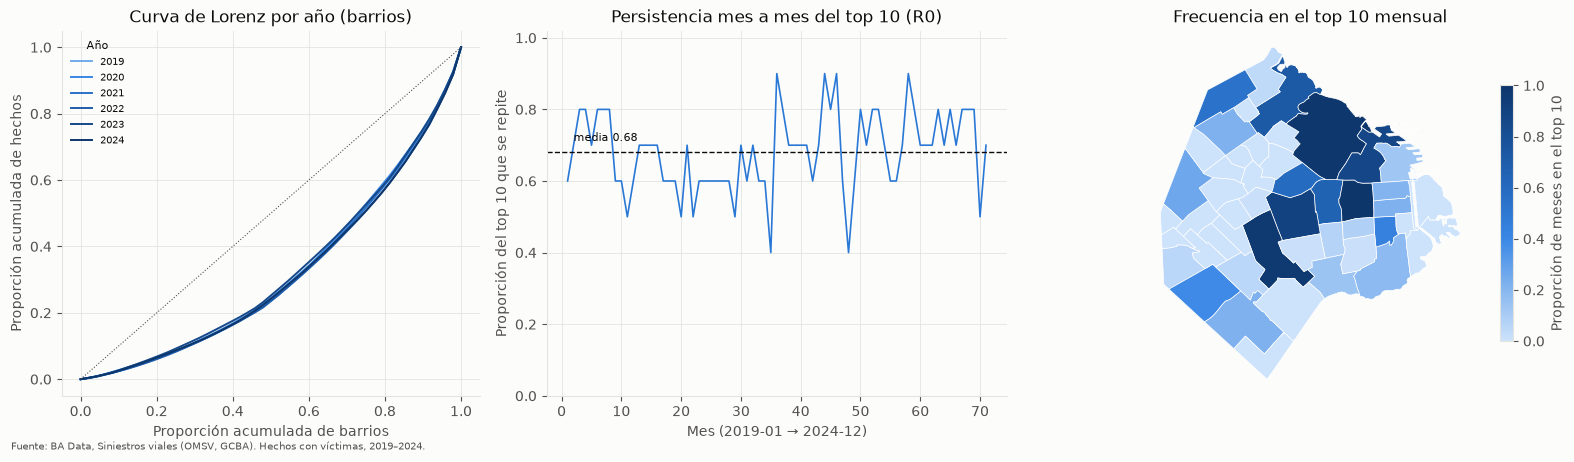

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1.1, 1.2]})
ax = axes[0]
for i, a in enumerate(yb.columns):
    xs = np.sort(yb[a].values); cum = np.r_[0, np.cumsum(xs) / xs.sum()]
    ax.plot(np.linspace(0, 1, len(cum)), cum, lw=1.4, color=SEQ(0.25 + 0.75 * i / (len(yb.columns) - 1)), label=str(a))
ax.plot([0, 1], [0, 1], color=INK2, lw=.8, ls=":"); ax.set_xlabel("Proporción acumulada de barrios"); ax.set_ylabel("Proporción acumulada de hechos")
ax.set_title("Curva de Lorenz por año (barrios)"); ax.legend(frameon=False, fontsize=7.5, title="Año", title_fontsize=8)
ax = axes[1]; ax.plot(range(1, len(rep) + 1), rep, color=CAT[0], lw=1.2); ax.set_ylim(0, 1.02)
ax.axhline(np.mean(rep), color=INK, ls="--", lw=1); ax.set_xlabel("Mes (2019-01 → 2024-12)")
ax.set_ylabel("Proporción del top 10 que se repite"); ax.set_title("Persistencia mes a mes del top 10 (R0)")
ax.text(2, np.mean(rep) + .03, f"media {np.mean(rep):.2f}", fontsize=8, color=INK)
gtop = barrios.merge(freq_top.rename("freq").reset_index(), on="barrio")
gtop.plot(column="freq", cmap=SEQ, ax=axes[2], legend=True, edgecolor="white", lw=.5, vmin=0, vmax=1, legend_kwds={"shrink": .7, "label": "Proporción de meses en el top 10"})
axes[2].set_axis_off(); axes[2].set_title("Frecuencia en el top 10 mensual")
fig.tight_layout(); save(fig, "f5_concentracion_persistencia")

**Lectura (5).**
- **Evidencia.**
  - El Gini entre barrios es estable: 0,345–0,370 por año.
  - El I de Moran global de la **densidad** es **0,47** (p de permutación = 0,0001; E[I] ≈ −0,02); el de los **conteos** es 0,21 (p = 0,008). La vecindad *queen* da una media de 5,2 vecinos y no hay islas.
  - El top 10 anual tiene un Jaccard de 0,82 entre años consecutivos (0,54 entre 2021 y 2022). Hay **7 barrios en el top 10 todos los años**: Almagro, Balvanera, Belgrano, Caballito, Flores, Palermo y Recoleta.
  - En promedio, **el 68 % del top 10 mensual se repite el mes siguiente** (rango 40–90 %). Balvanera está en el top 10 en el 100 % de los meses, Palermo en el 98,6 %, Flores en el 97,2 %, Caballito en el 90,3 % y Recoleta en el 86,1 %. **21 barrios nunca entran** al top 10.
  - **Microescala (grilla de 250 m).** El 5 % superior de las celdas reúne el 23,1 % de los hechos. Su superposición entre 2022 y 2024 es baja (Jaccard 0,33), aunque el orden general de las celdas se mantiene moderadamente (Spearman 0,72).
- **Interpretación.**
  - La carga está concentrada y espacialmente agrupada: las densidades altas son contiguas en el centro. Esto justifica incluir atributos de vecindad (rezagos espaciales) en el Paso 06.
  - La persistencia es muy alta a escala de barrio. Unos cinco barrios son positivos casi seguros cada mes, y la incertidumbre real del top 10 se concentra en las plazas restantes: ahí está el margen de un modelo frente a la persistencia.
  - A microescala, los *hotspots* son menos persistentes, lo que es consistente con la decisión D1 y con lo que anticipa H7. Es una observación preliminar, no un contraste formal.
- **Limitaciones.** Con 48 unidades, el I de Moran tiene poca potencia y depende de la partición en barrios (problema de la unidad de área modificable). La prueba de permutación supone intercambiabilidad. Los conteos mezclan tamaño y concentración (análisis 2).

## 6. Comparación de períodos, incluida la pandemia

| Período | Meses | Nota |
|---|---|---|
| Prepandemia | 2019-01 a 2019-10 | Se excluyen 2019-11/12 (caída de registro) |
| Pandemia | 2020-03 a 2021-05 | Restricciones de movilidad |
| Pospandemia | 2021-06 a 2024-12 | — |

Se comparan el nivel mensual, la composición por modo, la madrugada, la proporción KSI y la distribución territorial (participación de cada barrio y correlación de rangos entre períodos). Enero y febrero de 2020 quedan como transición y no se asignan a ningún período.

In [13]:
def periodo(m):
    if "2019-01" <= m <= "2019-10": return "pre"
    if "2020-03" <= m <= "2021-05": return "pandemia"
    if m >= "2021-06": return "post"
    return None
h["periodo"] = h["mes"].map(periodo); pb["periodo"] = pb["mes"].map(periodo)
g = h.dropna(subset=["periodo"])
nmes = g.groupby("periodo")["mes"].nunique()
comp = pd.DataFrame({
    "meses": nmes, "hechos_por_mes": (g.groupby("periodo").size() / nmes).round(1),
    "ksi_pct": (g.groupby("periodo")["ksi"].mean() * 100).round(2),
    "madrugada_0_6_pct": (g.groupby("periodo")["hora_entera"].apply(lambda s: s.between(0, 5).mean()) * 100).round(1),
    "sd_modo_pct": (g.groupby("periodo")["modo5"].apply(lambda s: (s == "SD").mean()) * 100).round(1)})
gm = g[g["modo5"] != "SD"]
comp = comp.join(pd.crosstab(gm["periodo"], gm["modo5"], normalize="index").mul(100).round(1)[MODOS]).loc[["pre", "pandemia", "post"]]
shp = pb.dropna(subset=["periodo"]).groupby(["periodo", "barrio"])["y_hechos"].sum().unstack(0)
shp = shp / shp.sum()
rho = {f"{a}-{b}": round(float(stats.spearmanr(shp[a], shp[b]).statistic), 3) for a, b in [("pre", "pandemia"), ("pandemia", "post"), ("pre", "post")]}
dsh = ((shp["pandemia"] - shp["pre"]) * 100).sort_values()
comp.to_csv(TAB / "t6_periodos.csv"); dsh.to_csv(TAB / "t6_cambio_participacion_pre_pandemia_pp.csv")
M["periodos"] = {"tabla": comp.reset_index().to_dict(orient="records"), "spearman_participacion": rho,
                 "mayores_caidas_participacion_pandemia_pp": dsh.head(3).round(2).to_dict(),
                 "mayores_subas_participacion_pandemia_pp": dsh.tail(3).round(2).to_dict(),
                 "chi2_modo_pre_vs_pandemia_p": float(stats.chi2_contingency(pd.crosstab(gm["periodo"], gm["modo5"]).loc[["pre", "pandemia"]].values)[1])}
display(comp); print(rho); print("Δ participación pandemia − pre (pp):", dsh.head(3).round(2).to_dict(), dsh.tail(3).round(2).to_dict())

,meses,hechos_por_mes,ksi_pct,madrugada_0_6_pct,sd_modo_pct,MOTO,PEATON,BICICLETA,AUTO,TRANSPORTE PUBLICO
periodo,,,,,,,,,,
pre,10,905.8,4.63,7.9,7.9,43.6,18.2,10.8,13.4,6.5
pandemia,15,486.7,4.83,8.7,23.3,44.8,16.0,17.9,12.3,3.7
post,43,818.7,5.65,7.9,19.2,44.9,17.2,12.7,13.2,6.7


{'pre-pandemia': 0.941, 'pandemia-post': 0.954, 'pre-post': 0.964}
Δ participación pandemia − pre (pp): {'Colegiales': -0.77, 'Retiro': -0.55, 'Recoleta': -0.45} {'Constitucion': 0.61, 'Parque Chacabuco': 0.62, 'Mataderos': 0.67}


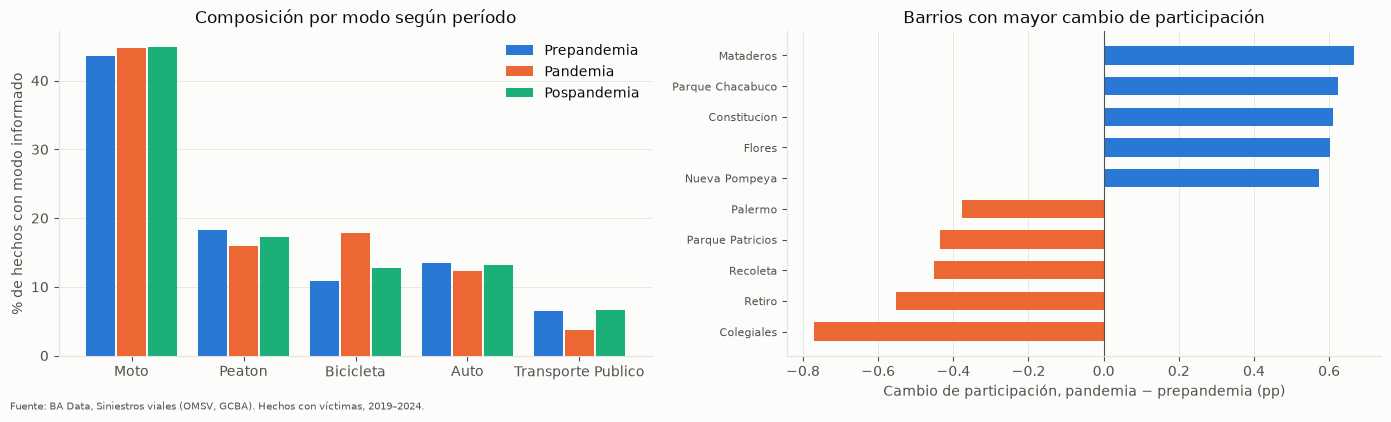

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(MODOS)); wdt = .26
for i, (p, lab) in enumerate([("pre", "Prepandemia"), ("pandemia", "Pandemia"), ("post", "Pospandemia")]):
    axes[0].bar(x + (i - 1) * (wdt + .02), comp.loc[p, MODOS], width=wdt, color=CAT[i], label=lab)
axes[0].set_xticks(x, [m.title() for m in MODOS]); axes[0].grid(axis="x", visible=False); axes[0].set_ylabel("% de hechos con modo informado")
axes[0].set_title("Composición por modo según período"); axes[0].legend(frameon=False)
top_ch = pd.concat([dsh.head(5), dsh.tail(5)])
axes[1].barh(range(len(top_ch)), top_ch.values, color=[CAT[1] if v < 0 else CAT[0] for v in top_ch.values], height=.6)
axes[1].set_yticks(range(len(top_ch)), top_ch.index, fontsize=8); axes[1].axvline(0, color=INK2, lw=.8); axes[1].grid(axis="y", visible=False)
axes[1].set_xlabel("Cambio de participación, pandemia − prepandemia (pp)"); axes[1].set_title("Barrios con mayor cambio de participación")
fig.tight_layout(); save(fig, "f6_periodos")

**Lectura (6).**
- **Evidencia.** El nivel mensual cae de 905,8 hechos (prepandemia) a 486,7 (pandemia; −46 %) y se recupera a 818,7 (pospandemia; −10 % respecto de la prepandemia). La composición cambia en la pandemia: la **bicicleta** pasa de 10,8 % a 17,9 % y vuelve a 12,7 %, y el **transporte público** baja de 6,5 % a 3,7 %. La proporción KSI sube levemente (4,6 %, 4,8 % y 5,7 %) y la madrugada se mantiene cerca del 8 %. La **geografía casi no cambia**: la correlación de Spearman de las participaciones por barrio es 0,94 entre prepandemia y pandemia, 0,95 entre pandemia y pospandemia, y 0,96 entre prepandemia y pospandemia. Los mayores cambios de participación no superan 0,8 pp: Colegiales −0,77, Retiro −0,55 y Recoleta −0,45; Mataderos +0,67, Parque Chacabuco +0,62 y Constitución +0,61.
- **Interpretación.** La pandemia fue un shock de **nivel y de composición modal**, no de distribución territorial. Hubo leves desplazamientos del centro y el norte hacia el sur y el oeste, compatibles con menos viajes al centro. Para el pronóstico, esto respalda un objetivo relativo por mes (D6: top 10), robusto a cambios de nivel, y la conservación de los meses de pandemia con una marca (D3) en lugar de eliminarlos.
- **Limitaciones.** La prepandemia dura solo 10 meses. El SD de modo sube en la pandemia (de 7,9 % a 23,3 %), lo que puede distorsionar la composición. Los contrastes son descriptivos.

## 7. Relación con la infraestructura vial disponible (solo descriptiva, D11)

> El callejero y los cruces semaforizados reflejan el **estado vigente en 2026** y no tienen fechas de vigencia verificables. Este análisis es **transversal y descriptivo**: no se usa para pronosticar ni permite afirmar efectos causales. Además, más vías o más semáforos suelen indicar más tránsito, que no se observa.

Se calcula, por barrio:
- km de red vial por tipo (`tipo_c` del callejero, recortado por barrio);
- proporción de km de avenidas;
- cruces semaforizados por km², según el campo `barrio` de F13, porque sus coordenadas están mal formadas.

Luego se mide su asociación (Spearman) con la densidad de hechos de 2022–2024. A escala ciudad, se compara la proporción de hechos en avenidas (`tipo_de_via`, 2020–2024, sin SD) con la proporción de km de avenidas.

In [15]:
def norm_txt(s):
    return "".join(c for c in unicodedata.normalize("NFKD", str(s)) if not unicodedata.combining(c)).upper().strip()
call = gpd.read_file(RAW / "red_vial" / "callejero.geojson").to_crs(CRS_CABA)
call["clase"] = np.select([call["tipo_c"].isin(["AVENIDA", "BOULEVARD"]), call["tipo_c"].astype(str).str.contains("AUTOPISTA")], ["avenida", "autopista"], "otras")
bp = barrios.to_crs(CRS_CABA)[["barrio", "geometry"]]
seg = gpd.overlay(call[["clase", "geometry"]], bp, how="intersection", keep_geom_type=True)
seg["km"] = seg.length / 1000
km = seg.pivot_table(index="barrio", columns="clase", values="km", aggfunc="sum", fill_value=0)
km["km_total"] = km.sum(axis=1); km["pct_km_avenida"] = (km["avenida"] / km["km_total"] * 100).round(1)
cru = pd.read_csv(RAW / "red_vial" / "cruces-semaforizados.csv", dtype=str, sep=None, engine="python", encoding="utf-8-sig")
cmap_b = {norm_txt(b): b for b in barrios["barrio"]}
cru["barrio_n"] = cru["barrio"].map(lambda s: cmap_b.get(norm_txt(s)) if pd.notna(s) else None)
sem = cru["barrio_n"].value_counts()
inf = tb[["area_km2"]].join(km).join(sem.rename("semaforos")).fillna({"semaforos": 0})
inf["km_vias_por_km2"] = (inf["km_total"] / inf["area_km2"]).round(2); inf["semaforos_por_km2"] = (inf["semaforos"] / inf["area_km2"]).round(2)
rec = pb[pb["anio"].between(2022, 2024)].groupby("barrio")["y_hechos"].sum()
inf["hechos_km2_anio_2022_2024"] = (rec / 3 / inf["area_km2"]).round(1)
inf.to_csv(TAB / "t7_infraestructura_descriptiva.csv")
assoc = {c: round(float(stats.spearmanr(inf[c], inf["hechos_km2_anio_2022_2024"]).statistic), 3)
         for c in ["km_vias_por_km2", "pct_km_avenida", "semaforos_por_km2"]}
tv = h[(h["fecha"].dt.year >= 2020) & (h["tipo_de_via"] != "SD")]
pct_av_hechos = float(tv["tipo_de_via"].isin(["AVENIDA", "AV. GRAL. PAZ"]).mean() * 100)
pct_av_km = float(km["avenida"].sum() / km["km_total"].sum() * 100)
M["infraestructura_descriptiva"] = {"spearman_con_densidad_hechos": assoc, "pct_hechos_en_avenidas_2020_2024": round(pct_av_hechos, 1),
                                    "pct_km_avenidas_ciudad": round(pct_av_km, 1), "km_total_red": round(float(km["km_total"].sum()), 0),
                                    "cruces_sin_barrio_asignable": int(cru["barrio_n"].isna().sum()),
                                    "hechos_tipo_via_sd_2020_2024_pct": round(float((h.loc[h["fecha"].dt.year >= 2020, "tipo_de_via"] == "SD").mean() * 100), 1)}
print(M["infraestructura_descriptiva"])

{'spearman_con_densidad_hechos': {'km_vias_por_km2': 0.365, 'pct_km_avenida': -0.01, 'semaforos_por_km2': 0.767}, 'pct_hechos_en_avenidas_2020_2024': 64.3, 'pct_km_avenidas_ciudad': 23.5, 'km_total_red': 3437.0, 'cruces_sin_barrio_asignable': 106, 'hechos_tipo_via_sd_2020_2024_pct': 5.9}


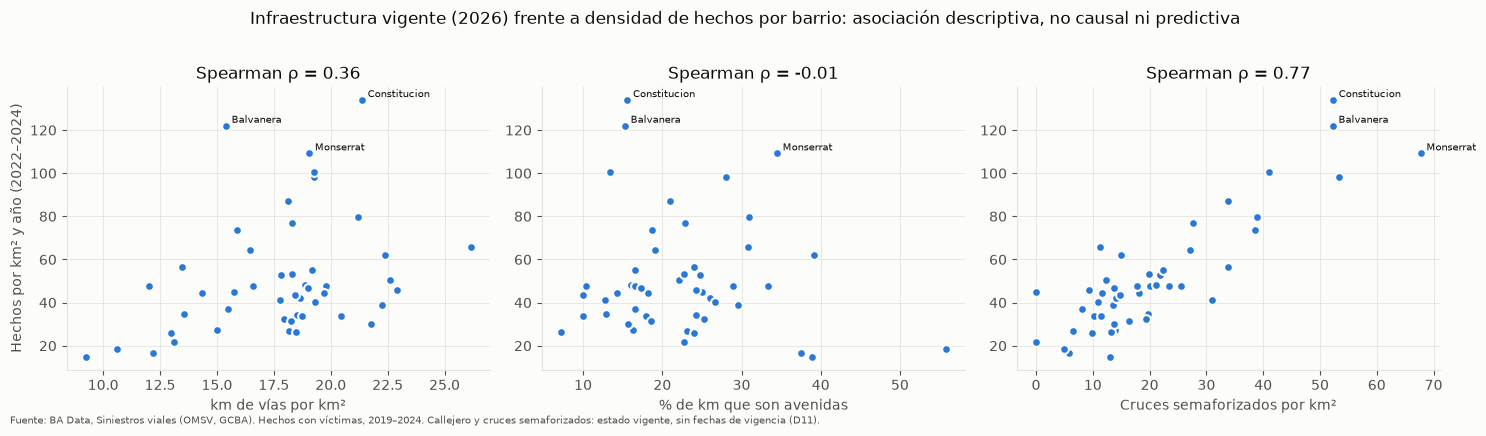

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.1))
for ax, c, lab in [(axes[0], "km_vias_por_km2", "km de vías por km²"), (axes[1], "pct_km_avenida", "% de km que son avenidas"), (axes[2], "semaforos_por_km2", "Cruces semaforizados por km²")]:
    ax.scatter(inf[c], inf["hechos_km2_anio_2022_2024"], s=40, color=CAT[0], edgecolor=SURFACE, lw=1.5)
    for b in inf["hechos_km2_anio_2022_2024"].nlargest(3).index: ax.annotate(b, (inf.loc[b, c], inf.loc[b, "hechos_km2_anio_2022_2024"]), fontsize=7.5, xytext=(4, 2), textcoords="offset points")
    ax.set_xlabel(lab); ax.set_title(f"Spearman ρ = {assoc[c]:.2f}")
axes[0].set_ylabel("Hechos por km² y año (2022–2024)")
fig.suptitle("Infraestructura vigente (2026) frente a densidad de hechos por barrio: asociación descriptiva, no causal ni predictiva", y=1.02)
fig.tight_layout(); save(fig, "f7_infraestructura", FUENTE + " Callejero y cruces semaforizados: estado vigente, sin fechas de vigencia (D11).")

**Lectura (7, descriptiva).**
- **Evidencia.**
  - Entre 2020 y 2024 (sin SD, que es el 5,9 %), el **64,3 % de los hechos ocurrió en avenidas**, que representan el **23,5 % de los km** de la red vial (3.437 km): unas 2,7 veces su peso en la red.
  - Por barrio, la densidad de hechos de 2022–2024 se asocia fuerte y positivamente con la densidad de cruces semaforizados (Spearman 0,77) y moderadamente con los km de vías por km² (0,36). No se asocia con la proporción de km de avenidas (−0,01).
- **Interpretación.** Las avenidas concentran la siniestralidad registrada mucho más que su longitud. La asociación con los semáforos refleja, muy probablemente, **centralidad y volumen de tránsito no observado**: donde hay más tránsito hay más semáforos y más siniestros. No indica que los semáforos causen siniestros, ni que los eviten. Por eso este resultado no cambia la decisión D11: la infraestructura actual no se usa para pronosticar.
- **Limitaciones.** La infraestructura es la vigente en 2026 y la relación es transversal entre barrios. Hay 106 cruces sin barrio asignable. `tipo_de_via` es la vía registrada en el sumario y en 2019 no está disponible.

## 8. Faltantes y posibles sesgos de registro

Se analizan:
- el faltante de coordenadas por año, gravedad y comuna informada;
- el SD del modo de la víctima por año;
- la discrepancia de geocodificación por año;
- la caída de registro de fines de 2019 (relación con el mismo período de otros años);
- la gravedad registrada como proporción de hechos, por año.

In [17]:
hh = h_all[h_all["particion"] == "desarrollo"]
sin_xy = pd.crosstab(hh["anio"], hh["gravedad"], values=hh["lat"].isna(), aggfunc="mean").mul(100).round(1)
sin_xy_c = hh[hh["comuna_fuente"].notna()].groupby("comuna_fuente")["lat"].apply(lambda s: round(s.isna().mean() * 100, 1))
sdm = hh.groupby("anio")["modo_victima"].apply(lambda s: round((s == "SD").mean() * 100, 1))
disc = hh.groupby("anio")["discrepancia_plana"].sum()
nd = hh[hh["mes"].str[5:].isin(["11", "12"])].groupby("anio").size()
ref_nd = hh[hh["mes"].str[5:].isin(["09", "10"])].groupby("anio").size()
ratio_nd = (nd / ref_nd).round(2)
grav = (hh.groupby("anio")["gravedad"].apply(lambda s: (s == "GRAVE").mean() * 100)).round(2)
tabla8 = pd.DataFrame({"sin_coord_pct_total": hh.groupby("anio")["lat"].apply(lambda s: round(s.isna().mean() * 100, 1)),
                       "sin_coord_pct_GRAVE": sin_xy["GRAVE"], "modo_SD_pct": sdm, "discrepancia_plana_n": disc,
                       "nov_dic_sobre_sep_oct": ratio_nd, "graves_pct": grav})
tabla8.to_csv(TAB / "t8_faltantes_sesgos.csv"); sin_xy_c.to_csv(TAB / "t8_sin_coordenada_por_comuna_fuente.csv")
M["faltantes"] = {"tabla": tabla8.reset_index().to_dict(orient="records"),
                  "sin_coord_por_comuna_rango_pct": [float(sin_xy_c.min()), float(sin_xy_c.max())],
                  "comuna_mayor_faltante": int(sin_xy_c.idxmax()), "spearman_graves_pct_vs_sin_coord_grave": round(float(stats.spearmanr(grav, sin_xy["GRAVE"]).statistic), 3)}
display(tabla8); print("Sin coordenada por comuna informada (%):", sin_xy_c.to_dict())

,sin_coord_pct_total,sin_coord_pct_GRAVE,modo_SD_pct,discrepancia_plana_n,nov_dic_sobre_sep_oct,graves_pct
anio,,,,,,
2019,5.2,5.9,9.7,4,0.61,3.67
2020,3.3,9.1,21.7,1,1.32,2.36
2021,6.6,27.7,29.5,0,1.00,4.58
2022,4.2,19.2,10.4,427,0.93,5.47
2023,2.9,12.6,11.8,21,0.98,3.59
2024,4.3,17.4,26.5,15,1.08,4.88


Sin coordenada por comuna informada (%): {1.0: 1.1, 2.0: 0.3, 3.0: 0.2, 4.0: 0.3, 5.0: 0.4, 6.0: 0.0, 7.0: 0.7, 8.0: 1.2, 9.0: 0.2, 10.0: 0.3, 11.0: 0.0, 12.0: 0.2, 13.0: 0.2, 14.0: 0.2, 15.0: 0.2}


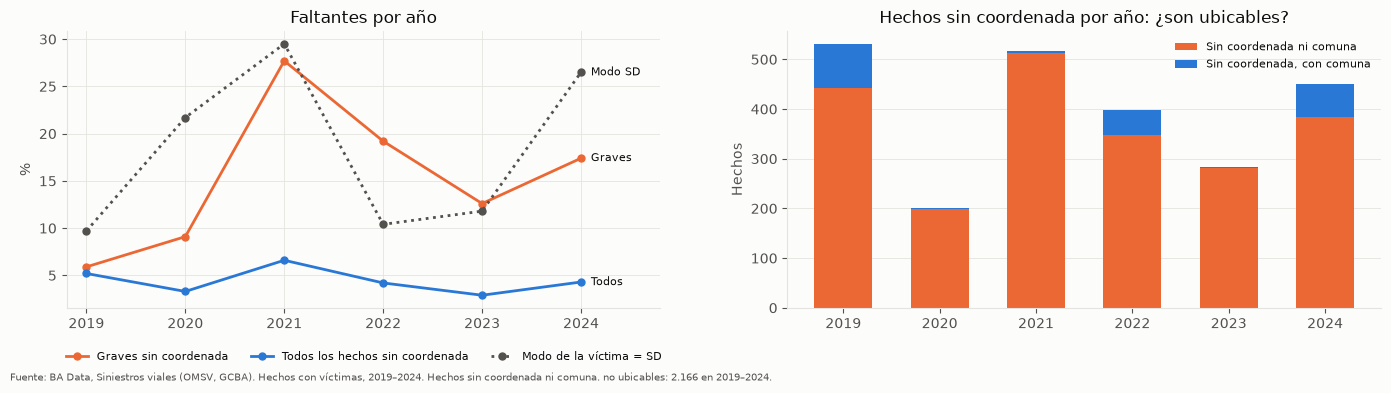

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
yrs = tabla8.index.astype(int)
axes[0].plot(yrs, tabla8["sin_coord_pct_GRAVE"], color=CAT[1], marker="o", ms=5, label="Graves sin coordenada")
axes[0].plot(yrs, tabla8["sin_coord_pct_total"], color=CAT[0], marker="o", ms=5, label="Todos los hechos sin coordenada")
axes[0].plot(yrs, tabla8["modo_SD_pct"], color=INK2, marker="o", ms=5, ls=":", label="Modo de la víctima = SD")
for col, lab in [("sin_coord_pct_GRAVE", "Graves"), ("sin_coord_pct_total", "Todos"), ("modo_SD_pct", "Modo SD")]:
    axes[0].annotate(lab, (yrs[-1] + .1, tabla8[col].iloc[-1]), fontsize=8, va="center")
axes[0].set_xlim(2018.8, 2024.8); axes[0].set_xticks(range(2019, 2025)); axes[0].set_ylabel("%"); axes[0].set_title("Faltantes por año")
axes[0].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.12), ncol=3)
ub = pd.crosstab(hh["anio"], np.select([hh["lat"].notna(), hh["comuna"].notna()], ["con coordenada", "solo comuna"], "sin ubicación"))
ub = ub[["solo comuna", "sin ubicación"]]
axes[1].bar(ub.index, ub["sin ubicación"], color=CAT[1], width=.6, label="Sin coordenada ni comuna")
axes[1].bar(ub.index, ub["solo comuna"], bottom=ub["sin ubicación"], color=CAT[0], width=.6, label="Sin coordenada, con comuna")
axes[1].set_ylabel("Hechos"); axes[1].set_title("Hechos sin coordenada por año: ¿son ubicables?"); axes[1].legend(frameon=False, fontsize=8); axes[1].grid(axis="x", visible=False)
M["faltantes"]["sin_coord_por_anio_ubicabilidad"] = ub.reset_index().to_dict(orient="records")
fig.tight_layout(); save(fig, "f8_faltantes", FUENTE + f" Hechos sin coordenada ni comuna, no ubicables: {int(ub['sin ubicación'].sum()):,} en 2019–2024.".replace(",", "."))

**Lectura (8).**
- **Evidencia.**
  - El faltante de coordenadas total va de 2,9 % a 6,6 % según el año. En los **graves** es mucho mayor y variable: 5,9 % en 2019, 27,7 % en 2021 y 17,4 % en 2024. Entre años, la proporción de graves registrados y el faltante de coordenadas de los graves se correlacionan (Spearman 0,66, con 6 años).
  - **Casi todos los hechos sin coordenada tampoco tienen comuna** (por ejemplo, 513 de 516 en 2021), así que su distribución territorial **no es identificable**.
  - La relación entre noviembre-diciembre y septiembre-octubre es **0,61 en 2019**, frente a 0,93–1,32 en los demás años.
  - Las discrepancias de geocodificación se concentran en 2022 (427).
  - El modo SD oscila entre 9,7 % y 29,5 %.
- **Interpretación.** Los registros de gravedad y de localización parecen depender de procesos de carga que cambian entre años. Una hipótesis compatible es que los graves identificados mediante el relevamiento hospitalario lleguen con menos información de ubicación. Por eso la gravedad territorial se mantiene **descriptiva** (D5). La caída de fines de 2019 se confirma como un problema de registro (D3).
- **Limitaciones.** Sin la respuesta institucional (consulta, preguntas 2 y 3), estas son hipótesis. El sesgo territorial de los faltantes no se puede medir directamente: en el peor caso, si los hechos sin ubicación se concentraran en algunos barrios, las participaciones podrían moverse hasta unos 4 pp.

## 9. Registro de métricas

In [19]:
(TAB / "eda_metrics.json").write_text(json.dumps(M, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Guardado:", (TAB / "eda_metrics.json").relative_to(ROOT))

Guardado: reports\tables\01_EDA\eda_metrics.json


### Conclusiones y qué pasa al paso siguiente

- **Qué aprendimos.** La siniestralidad registrada es estacional y diurna, afecta sobre todo a motociclistas y peatones, y se concentra en pocos barrios que se repiten mes a mes. Esa persistencia es la señal más fuerte para pronosticar.
- **Qué decisiones respalda.** Objetivo relativo por mes (top 10), robusto a cambios de nivel como la pandemia. Variables de nivel reciente, calendario, vecindad y superficie. «Sin dato» como categoría explícita. Gravedad e infraestructura solo descriptivas.
- **Qué no se puede afirmar.** Que un barrio sea más peligroso por persona o por viaje, ni que la infraestructura cause o evite siniestros.
- **Siguiente paso.** El notebook 02 traduce estos hallazgos en variables calculadas con información disponible al momento del pronóstico.
- **Dónde está el detalle.** [docs/eda_findings.md](../docs/eda_findings.md) y `reports/tables/01_EDA/eda_metrics.json`.